# **LMR  2026**


In [6]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.discrete.count_model import ZeroInflatedPoisson
from scipy.stats import weibull_min
from statsmodels.discrete.count_model import ZeroInflatedNegativeBinomialP
from scipy.stats import nbinom
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import lognorm, pareto, poisson, weibull_min
from scipy.stats import anderson, kstest, cramervonmises

In [7]:
#u_value = 0.95


## 1. Datos

### 1.1 Frecuencia

In [8]:
panel = pd.read_excel('/content/panel_SPP_D.xlsx')

print(panel['n_siniestros'].sum())

print(panel["exposicion_anual"].sum())

#panel = panel.dropna(subset=("n_siniestros","exposicion_anual"))
panel

81
2362.6027397260277


,Poliza,CERT,Fecha Ini,Fecha Fin,DuraciÃ³n,exposicion_anual,anio,n_siniestros,_merge
0,TA00000001,097-001,2025-12-30,2026-12-30,365,0.005479,2025,0,left_only
1,TA00000001,097-001,2025-12-30,2026-12-30,365,0.997260,2026,0,left_only
2,TA00000002,0001,2025-12-30,2026-12-30,364,0.005479,2025,0,left_only
3,TA00000002,0001,2025-12-30,2026-12-30,364,0.997260,2026,0,left_only
4,TA00000002,0002,2025-12-30,2026-12-30,364,0.005479,2025,0,left_only
...,...,...,...,...,...,...,...,...,...
4536,EE00000941,0000,2025-09-15,2026-09-15,365,0.706849,2026,0,left_only
4537,EE00000968,0000,2025-10-24,2026-10-24,365,0.189041,2025,0,left_only
4538,EE00000968,0000,2025-10-24,2026-10-24,365,0.813699,2026,0,left_only
4539,EE00000988,0000,2025-11-22,2026-11-22,365,0.109589,2025,0,left_only


In [9]:
######### Exposición anual

desc_expo = panel["exposicion_anual"].describe()
desc_expo

,exposicion_anual
count,4541.000000
mean,0.520282
std,0.285754
min,0.002740
25%,0.276712
50%,0.512329
75%,0.756164
max,1.000000


In [10]:
######### Distribución de siniestros

freq_counts = panel["n_siniestros"].value_counts().sort_index()

freq_table = pd.DataFrame({
    "n_siniestros": freq_counts.index,
    "frecuencia": freq_counts.values,
    "proporción": freq_counts.values / freq_counts.sum()
})

freq_table


,n_siniestros,frecuencia,proporción
0,0,4487,0.988108
1,1,48,0.010570
2,2,4,0.000881
3,7,1,0.000220
4,18,1,0.000220


### 1.2. Pólizas en vigor

Las pólizas en vigor se utilizan como base para las simulaciones de pérdidas anuales.

In [11]:
# Leer solo la pestaña y columna necesarias
df_pol = pd.read_excel(
    "Polizas Vigor pesos-dol con vigencias.xlsx",
#    sheet_name="Pesos Básica Depurada",
#    header=1,
    usecols=["POL"]
)

# Convertir a lista (opcional: quitar NA)
lista_pol = df_pol["POL"].dropna().astype(str).unique().tolist()

In [12]:
panel_sub = panel[
    (panel["Poliza"].astype(str).isin(lista_pol)) #&
#    (panel["anio"] == 2026)
].copy()

In [13]:
panel.sort_values("exposicion_anual")

,Poliza,CERT,Fecha Ini,Fecha Fin,DuraciÃ³n,exposicion_anual,anio,n_siniestros,_merge
3607,EC00000225,0000,2023-01-01,2024-01-01,365,0.00274,2024,0,left_only
3898,EC00000399,0000,2024-01-01,2025-01-01,366,0.00274,2025,0,left_only
3590,EC00000217,0000,2022-12-31,2023-12-31,365,0.00274,2022,0,left_only
2327,EE00000507,0000,2024-04-15,2025-01-01,261,0.00274,2025,0,left_only
3359,EC00000079,0000,2021-12-31,2022-12-31,365,0.00274,2021,0,left_only
...,...,...,...,...,...,...,...,...,...
4499,EE00000447,0000,2023-12-29,2027-12-29,1461,1.00000,2026,0,left_only
3897,EC00000399,0000,2024-01-01,2025-01-01,366,1.00000,2024,0,left_only
3910,EC00000406,0000,2023-12-30,2024-12-30,366,1.00000,2024,0,left_only
4530,EE00000752,0000,2025-02-13,2029-02-13,1461,1.00000,2027,0,left_only


In [14]:
print(panel_sub["Poliza"].nunique())

print(panel_sub["exposicion_anual"].sum())

panel_sub

586
874.1041095890412


,Poliza,CERT,Fecha Ini,Fecha Fin,DuraciÃ³n,exposicion_anual,anio,n_siniestros,_merge
2,TA00000002,0001,2025-12-30,2026-12-30,364,0.005479,2025,0,left_only
3,TA00000002,0001,2025-12-30,2026-12-30,364,0.997260,2026,0,left_only
4,TA00000002,0002,2025-12-30,2026-12-30,364,0.005479,2025,0,left_only
5,TA00000002,0002,2025-12-30,2026-12-30,364,0.997260,2026,0,left_only
6,TA00000002,0003,2026-01-07,2027-01-07,364,0.983562,2026,1,left_only
...,...,...,...,...,...,...,...,...,...
4532,EE00000752,0000,2025-02-13,2029-02-13,1461,0.120548,2029,0,left_only
4537,EE00000968,0000,2025-10-24,2026-10-24,365,0.189041,2025,0,left_only
4538,EE00000968,0000,2025-10-24,2026-10-24,365,0.813699,2026,0,left_only
4539,EE00000988,0000,2025-11-22,2026-11-22,365,0.109589,2025,0,left_only


In [15]:
########### Exposición anual

desc_expo_vigor = panel_sub["exposicion_anual"].describe()
desc_expo_vigor

,exposicion_anual
count,1588.000000
mean,0.550443
std,0.308242
min,0.005479
25%,0.276712
50%,0.556164
75%,0.830137
max,1.000000


### 1.3 Severidad


In [16]:
df_siniestros = pd.read_csv(
    "Siniestros_ramo_112.csv",
)

df_siniestros

,No..Reclamación,Año,Póliza,Producto,Suma Asegurada,Cobertura,Moneda,Estimado + aumento - disminución...8,Estimado + aumento - disminución...9,Garantía,Monto,Fecha Ocurrido
0,1,2021,00000005,EQUIPO CONTRATISTAS,422100.00,0,10,243203.27,243203.27,234761.27,243203.27,2021/05/21 00:00:00
1,2,2022,EE00000051,EQUIPO ELECTRONICO,21545940.00,0,10,24975.54,24975.54,22477.99,24975.54,2022/08/25 00:00:00
2,4,2022,EC00000173,EQUIPO CONTRATISTAS,22000.00,0,10,29200.00,542200.00,24300.00,542200.00,2022/12/13 00:00:00
3,4,2022,EC00000173,EQUIPO CONTRATISTAS,22000.00,0,20,29200.00,542200.00,24300.00,542200.00,2022/12/13 00:00:00
4,DA-CYB-0239,2026,RCYB000000042,RIESGOS CIBERNETICOS,150000.00,0,20,1.00,20.00,0.00,20.00,2026/04/13 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...
77,DA-TA-0238,2026,TA00000002,EQUIPO ELECTRONICO,15085.34,0,10,30170.68,30170.68,11314.00,30170.68,2026/04/21 00:00:00
78,DA-TA-0243,2026,TA00000001,EQUIPO ELECTRONICO,9999.00,0,10,19998.00,19998.00,0.00,19998.00,2026/04/27 00:00:00
79,DA-TA-0248,2026,TA00000001,EQUIPO ELECTRONICO,22438.00,0,10,44876.16,44876.16,0.00,44876.16,2026/05/20 00:00:00
80,DA-EC-0244,2026,EC00000654,EQUIPO CONTRATISTAS,238000.00,0,20,238000.00,4760000.00,202300.00,4760000.00,2026/03/25 00:00:00


In [17]:
df_siniestros["Monto"]

,Monto
0,243203.27
1,24975.54
2,542200.00
3,542200.00
4,20.00
...,...
77,30170.68
78,19998.00
79,44876.16
80,4760000.00


In [18]:
siniestros_pesos = df_siniestros[
    df_siniestros["Monto"] > 0
]

siniestros_pesos = siniestros_pesos["Monto"]

siniestros_pesos


,Monto
0,243203.27
1,24975.54
2,542200.00
3,542200.00
4,20.00
...,...
77,30170.68
78,19998.00
79,44876.16
80,4760000.00


In [19]:
# Descripción de percentiles

desc_sev = siniestros_pesos.describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

pd.options.display.float_format = '{:,.0f}'.format
desc_sev

,Monto
count,82
mean,"247,029"
std,"797,711"
min,20
50%,"19,285"
75%,"53,307"
90%,"525,380"
95%,"1,320,032"
99%,"4,760,000"
max,"4,760,000"


In [20]:
# Resumen de severidades

sev_summary = pd.DataFrame({
    "Estadístico": [
        "Observaciones",
        "Mínimo",
        "P25",
        "Mediana",
        "Media",
        "P75",
        "P90",
        "P95",
        "P99",
        "Máximo"
    ],
    "Valor": [
        siniestros_pesos.count(),
        siniestros_pesos.min(),
        siniestros_pesos.quantile(0.25),
        siniestros_pesos.median(),
        siniestros_pesos.mean(),
        siniestros_pesos.quantile(0.75),
        siniestros_pesos.quantile(0.90),
        siniestros_pesos.quantile(0.95),
        siniestros_pesos.quantile(0.99),
        siniestros_pesos.max()
    ]
})

sev_summary

,Estadístico,Valor
0,Observaciones,82
1,Mínimo,20
2,P25,"10,044"
3,Mediana,"19,285"
4,Media,"247,029"
5,P75,"53,307"
6,P90,"525,380"
7,P95,"1,320,032"
8,P99,"4,760,000"
9,Máximo,"4,760,000"


In [21]:
skewness = siniestros_pesos.skew()
kurtosis = siniestros_pesos.kurtosis()

pd.DataFrame({
    "Métrica": ["Asimetría", "Curtosis"],
    "Valor": [skewness, kurtosis]
})

,Métrica,Valor
0,Asimetría,5
1,Curtosis,25


## 2. Ajustar frecuencia

### 2.1. Poisson con inflación de cero

#### 2.1.1. Fit

In [22]:
y = panel["n_siniestros"]
X = sm.add_constant(pd.Series(1, index=panel.index))

zip_model = ZeroInflatedPoisson(
    y,
    X,
    exog_infl=X,
    offset=(panel["exposicion_anual"]),
    inflation="logit"
)

zip_res = zip_model.fit(method="bfgs")
print(zip_res.summary())
#offset=np.log(panel["exposicion_anual"]),

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/tsatools.py:166: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  x = pd.concat(x[::order], axis=1)


Optimization terminated successfully.
         Current function value: 0.079598
         Iterations: 10
         Function evaluations: 20
         Gradient evaluations: 20
                     ZeroInflatedPoisson Regression Results                    
Dep. Variable:            n_siniestros   No. Observations:                 4541
Model:             ZeroInflatedPoisson   Df Residuals:                     4540
Method:                            MLE   Df Model:                            0
Date:                 Sun, 22 Nov 2026   Pseudo R-squ.:              -1.151e-08
Time:                         08:18:10   Log-Likelihood:                -361.45
converged:                        True   LL-Null:                       -361.45
Covariance Type:             nonrobust   LLR p-value:                       nan
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
inflate_0      3.6935      0.1

In [23]:
panel.isna().sum().sum()

np.int64(0)

#### 3.1.2. Extraer parámetros

In [24]:
beta_pois = zip_res.params.loc[0]
beta_infl = zip_res.params.loc["inflate_0"]

lambda_hat = float(np.exp(beta_pois))
p_zero = float(1 / (1 + np.exp(-beta_infl)))

print("Lambda:", lambda_hat)
print("Prob cero estructural:", p_zero)

Lambda: 0.3954788156177575
Prob cero estructural: 0.9757203689907209


#### 3.1.3. Validación

##### 3.1.3.1. Media

In [25]:
mu_hat = (
    panel["exposicion_anual"]
    * (1 - p_zero)
    * lambda_hat
)

mean_obs = panel["n_siniestros"].mean()

print("Media observada :", mean_obs)
print("Media modelada  :", mu_hat.mean())

Media observada : 0.017837480731116493
Media modelada  : 0.004995793843242869


##### 3.1.3.2 Varianza vs media

In [26]:
var_obs = panel["n_siniestros"].var()

print("Media:", mean_obs)
print("Varianza:", var_obs)
print("Var / Media:", var_obs / mean_obs)

Media: 0.017837480731116493
Varianza: 0.09593726080635681
Var / Media: 5.378408658292177


In [27]:
#resid = zip_results.resid_response
#resid =np.log(resid)
#zip_results.predict(which="mean")[:5]
#zip_results.predict(which="prob-zero")[:5]

##### 3.1.3.3. Gráfica

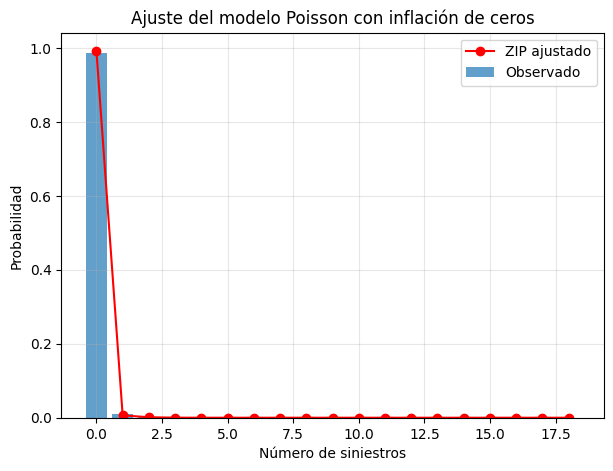

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

# Datos observados
y = panel["n_siniestros"]
counts_obs = y.value_counts().sort_index()
freq_obs = counts_obs / len(y)

# Parámetros del modelo
p0 = p_zero          # prob. de cero estructural
lam = lambda_hat     # intensidad Poisson

# Soporte
k = np.arange(0, counts_obs.index.max() + 1)

# Probabilidades teóricas ZIP
pmf_zip = np.zeros_like(k, dtype=float)
pmf_zip[0] = p0 + (1 - p0) * poisson.pmf(0, lam)
pmf_zip[1:] = (1 - p0) * poisson.pmf(k[1:], lam)

# Gráfica
plt.figure(figsize=(7,5))
plt.bar(freq_obs.index, freq_obs.values, alpha=0.7, label="Observado")
plt.plot(k, pmf_zip, marker="o", color="red", label="ZIP ajustado")

plt.xlabel("Número de siniestros")
plt.ylabel("Probabilidad")
plt.title("Ajuste del modelo Poisson con inflación de ceros")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


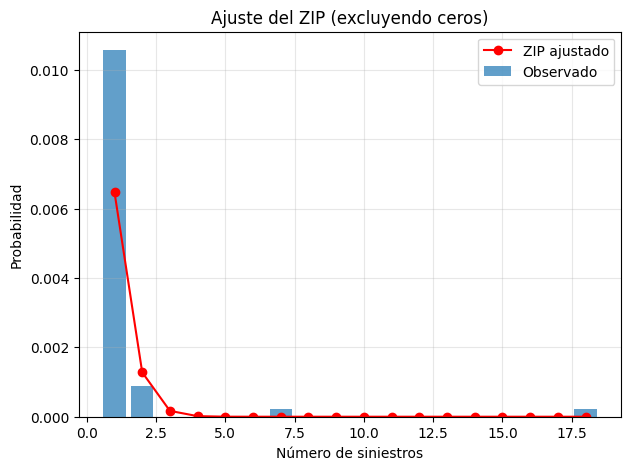

In [29]:
# Filtrar valores mayores a cero
k_pos = k[1:]
freq_obs_pos = freq_obs.loc[1:]
pmf_zip_pos = pmf_zip[1:]

plt.figure(figsize=(7,5))
plt.bar(freq_obs_pos.index, freq_obs_pos.values, alpha=0.7, label="Observado")
plt.plot(k_pos, pmf_zip_pos, marker="o", color="red", label="ZIP ajustado")

plt.xlabel("Número de siniestros")
plt.ylabel("Probabilidad")
plt.title("Ajuste del ZIP (excluyendo ceros)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 4. Ajustar severidad


### 4.1. Lognormal

#### 4.1.1. Fit

In [30]:
sev_obs = siniestros_pesos

sigma_hat, loc_hat, scale_hat = lognorm.fit(sev_obs, floc=0)

print("shape :", sigma_hat)
print("scale :", scale_hat)
print("loc :", loc_hat)

shape : 1.875123535054356
scale : 28548.455391684212
loc : 0


#### 4.1.2. Extraer parámetros

In [31]:
mu_log = np.log(scale_hat)
var_log = sigma_hat**2

print("mu_log:", mu_log)
print("var_log:", var_log)
print('sd', sigma_hat)

mu_log: 10.259358111753144
var_log: 3.516088271714745
sd 1.875123535054356


In [32]:
from scipy.stats import norm

# Intervalo de confianza para los parámetros

# Datos log-transformados
y = np.log(sev_obs)
n = len(y)

mu_hat = np.mean(y)
sigma_hat = np.std(y, ddof=0)  # MLE

z = norm.ppf(0.975)

# Errores estándar
se_mu = sigma_hat / np.sqrt(n)
se_sigma = sigma_hat / np.sqrt(2 * n)

# Intervalos de confianza
ci_mu = (mu_hat - z * se_mu, mu_hat + z * se_mu)
ci_sigma = (sigma_hat - z * se_sigma, sigma_hat + z * se_sigma)

print("mu_hat:", mu_hat)
print("IC 95% mu:", ci_mu)

print("sigma_hat:", sigma_hat)
print("IC 95% sigma:", ci_sigma)

mu_hat: 10.259358111753144
IC 95% mu: (np.float64(9.853502972605975), np.float64(10.665213250900313))
sigma_hat: 1.875123535054357
IC 95% sigma: (np.float64(1.5881406139839838), np.float64(2.16210645612473))


#### 4.1.3. Comparación empírica vs teórica

In [33]:
print("Media empírica :", sev_obs.mean())
print("Media lognormal:", lognorm.mean(s=sigma_hat, scale=scale_hat))

for q in [0.5, 0.9, 0.95, 0.99]:
    print(
        f"Q{int(q*100)} emp:",
        np.quantile(sev_obs, q),
        " | Q model:",
        lognorm.ppf(q, s=sigma_hat, scale=scale_hat)
    )

Media empírica : 247029.0635424756
Media lognormal: 165611.87836374063
Q50 emp: 19284.665  | Q model: 28548.455391684212
Q90 emp: 525380.0000000009  | Q model: 315661.4677399217
Q95 emp: 1320031.722  | Q model: 623847.8948405684
Q99 emp: 4760000.0  | Q model: 2239017.6109459293


#### 4.1.4. Pruebas de Bondad de Ajuste

##### 4.1.4.1. QQ Plot

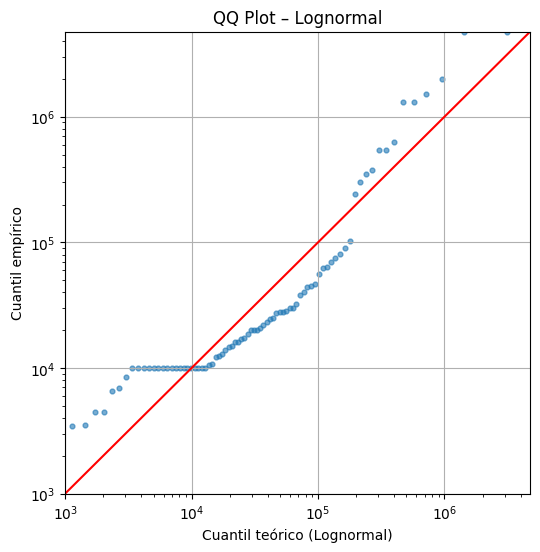

In [34]:
# 1. Ordenar severidades empíricas
sev_sorted = np.sort(sev_obs)
n = len(sev_sorted)

# 2. Probabilidades empíricas
probs = (np.arange(1, n + 1) - 0.5) / n

# 3. Cuantiles teóricos lognormal
theo_q = lognorm.ppf(
    probs,
    s=sigma_hat,
    loc=loc_hat,
    scale=scale_hat
)

# 4. Límites comunes para ambos ejes
q_min = min(sev_sorted.min(), theo_q.min())
q_max = max(sev_sorted.max(), theo_q.max())

# 5. QQ plot
plt.figure(figsize=(6, 6))
plt.scatter(theo_q, sev_sorted, s=12, alpha=0.6)
plt.plot([q_min, q_max], [q_min, q_max], color="red")

plt.ylim(1e3, q_max)
plt.xlim(1e3, q_max)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Cuantil teórico (Lognormal)")
plt.ylabel("Cuantil empírico")
plt.title("QQ Plot – Lognormal")
plt.grid(True)

plt.show()


##### 4.1.4.2. PP Plot

In [35]:
def pp_plot(p_emp, p_theo, title):
    plt.figure(figsize=(6, 6))
    plt.scatter(p_theo, p_emp, s=18, alpha=0.7)
    plt.plot([0, 1], [0, 1], color="red", lw=2)
    plt.xlabel("Probabilidad teórica")
    plt.ylabel("Probabilidad empírica")
    plt.title(title)
    plt.grid(True)
    plt.show()

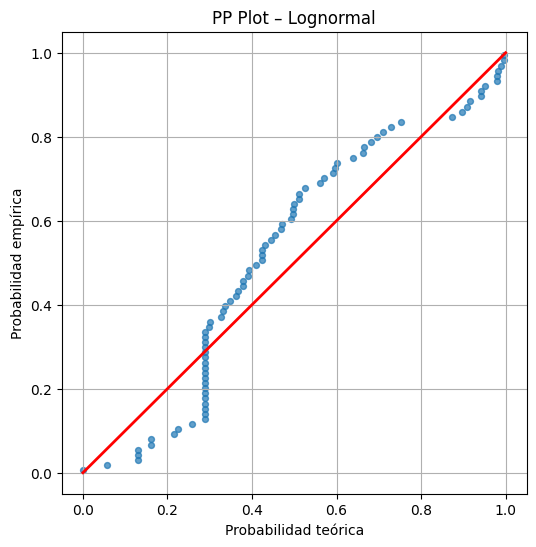

In [36]:
# 1. Ordenar datos
sev_sorted = np.sort(sev_obs)
n = len(sev_sorted)

# 2. Probabilidades empíricas
p_emp = (np.arange(1, n + 1) - 0.5) / n

# 3. Probabilidades teóricas lognormal
p_theo_lognorm = lognorm.cdf(
    sev_sorted,
    s=sigma_hat,
    loc=loc_hat,
    scale=scale_hat
)

# 4. PP plot
pp_plot(p_emp, p_theo_lognorm, "PP Plot – Lognormal")


##### 4.1.4.3. Kolmogorov-Smirnov Test

In [37]:
ks_ln = kstest(
    sev_obs,
    'lognorm',
    args=(sigma_hat, loc_hat, scale_hat)
)

print("KS statistic:", ks_ln.statistic)
print("KS p-value:", ks_ln.pvalue)


KS statistic: 0.16678304043545783
KS p-value: 0.018373488974257546


##### 4.1.4.4. Anderson Test

In [38]:
# Transformar a normal usando log
log_sev = np.log(sev_obs)

ad_ln = anderson(log_sev, dist="norm")

print("AD statistic:", ad_ln.statistic)
print("Critical values:", ad_ln.critical_values)
print("Significance levels:", ad_ln.significance_level)

AD statistic: 3.7735616975658957
Critical values: [0.551 0.628 0.753 0.878 1.045]
Significance levels: [15.  10.   5.   2.5  1. ]


##### 4.1.4.5. Cramer-von-Mises Test

In [39]:
cvm_ln = cramervonmises(
    sev_obs,
    lambda x: lognorm.cdf(x, s=sigma_hat, loc=loc_hat, scale=scale_hat)
)

print("CvM statistic:", cvm_ln.statistic)
print("CvM p-value:", cvm_ln.pvalue)

CvM statistic: 0.6774794008861568
CvM p-value: 0.014230518461639363


##### 4.1.4.6. AIC y BIC

In [40]:
def aic_bic(loglik, k, n):
    aic = 2*k - 2*loglik
    bic = k*np.log(n) - 2*loglik
    return aic, bic


In [41]:
loglik_ln = np.sum(lognorm.logpdf(sev_obs, s=sigma_hat, scale=scale_hat))
aic_ln, bic_ln = aic_bic(loglik_ln, k=2, n=len(sev_obs))

In [42]:
print('AIC: ', aic_ln)
print('BIC: ', bic_ln)

AIC:  2022.3432747618356
BIC:  2027.1567132563641


#### 4.1.5. Simulación de pérdidas anuales

In [43]:
import numpy as np
import pandas as pd
from scipy.stats import poisson, lognorm

def sim_annual_loss_zip_lognormal_detail(
    panel_sub,
    lambda_hat,
    p_zero,
    sigma,
    loc,
    scale,
    retention=12_000_000
):
    n = len(panel_sub)

    # Zeros estructurales
    is_active = np.random.uniform(size=n) > p_zero

    # Frecuencia Poisson (ANUAL)
    mu = lambda_hat * panel_sub["exposicion_anual"].values
    freq = np.zeros(n, dtype=int)
    freq[is_active] = poisson.rvs(mu[is_active])

    n_claims = int(freq.sum())

    if n_claims == 0:
        return 0.0, np.array([]), np.array([]), 0

    # Severidad
    sev = lognorm.rvs(
        s=sigma,
        loc=loc,
        scale=scale,
        size=n_claims
    )

    sev_retained = np.minimum(sev, retention)

    total_loss = sev_retained.sum()

    return total_loss, sev, sev_retained, n_claims


In [44]:
def montecarlo_annual_losses_detail(
    sim_func,
    n_sim=2_000_000,
    random_seed=123,
    **sim_kwargs
):
    np.random.seed(random_seed)

    losses = np.zeros(n_sim)
    freqs = np.zeros(n_sim, dtype=int)

    severities_sim_all = []
    severities_ret_all = []

    for i in range(n_sim):
        L, sev_sim, sev_ret, n = sim_func(**sim_kwargs)

        losses[i] = L
        freqs[i] = n

        severities_sim_all.append(sev_sim)
        severities_ret_all.append(sev_ret)

        if (i + 1) % 5_000 == 0:
            print(f"{i + 1:,} simulaciones")

    return losses, severities_sim_all, severities_ret_all, freqs


In [45]:

losses, sev_sim_all, sev_ret_all, freqs = montecarlo_annual_losses_detail(
    sim_func=sim_annual_loss_zip_lognormal_detail,
    n_sim=2_000_000,
    panel_sub=panel_sub,
    lambda_hat=lambda_hat,
    p_zero=p_zero,
    sigma=sigma_hat,
    loc=loc_hat,
    scale=scale_hat
)




5,000 simulaciones
10,000 simulaciones
15,000 simulaciones
20,000 simulaciones
25,000 simulaciones
30,000 simulaciones
35,000 simulaciones
40,000 simulaciones
45,000 simulaciones
50,000 simulaciones
55,000 simulaciones
60,000 simulaciones
65,000 simulaciones
70,000 simulaciones
75,000 simulaciones
80,000 simulaciones
85,000 simulaciones
90,000 simulaciones
95,000 simulaciones
100,000 simulaciones
105,000 simulaciones
110,000 simulaciones
115,000 simulaciones
120,000 simulaciones
125,000 simulaciones
130,000 simulaciones
135,000 simulaciones
140,000 simulaciones
145,000 simulaciones
150,000 simulaciones
155,000 simulaciones
160,000 simulaciones
165,000 simulaciones
170,000 simulaciones
175,000 simulaciones
180,000 simulaciones
185,000 simulaciones
190,000 simulaciones
195,000 simulaciones
200,000 simulaciones
205,000 simulaciones
210,000 simulaciones
215,000 simulaciones
220,000 simulaciones
225,000 simulaciones
230,000 simulaciones
235,000 simulaciones
240,000 simulaciones
245,000 simu

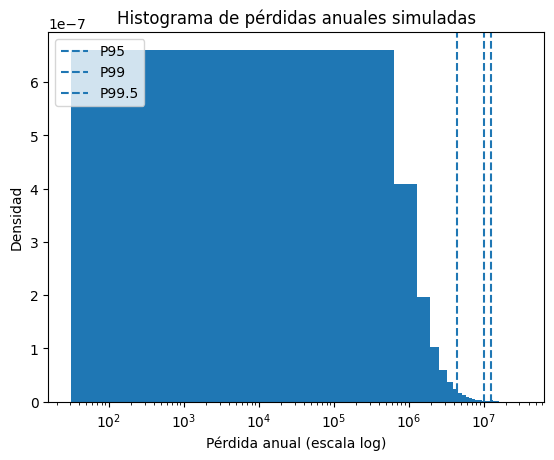

In [46]:
plt.figure()

losses_pos = losses[losses > 0]
plt.hist(losses_pos, bins=50, density=True)
plt.xscale("log")

for q, label in zip([0.95, 0.99, 0.995], ["P95", "P99", "P99.5"]):
    plt.axvline(
        np.quantile(losses, q),
        linestyle="--",
        label=label
    )

plt.xlabel("Pérdida anual (escala log)")
plt.ylabel("Densidad")
plt.title("Histograma de pérdidas anuales simuladas")
plt.legend()
plt.show()


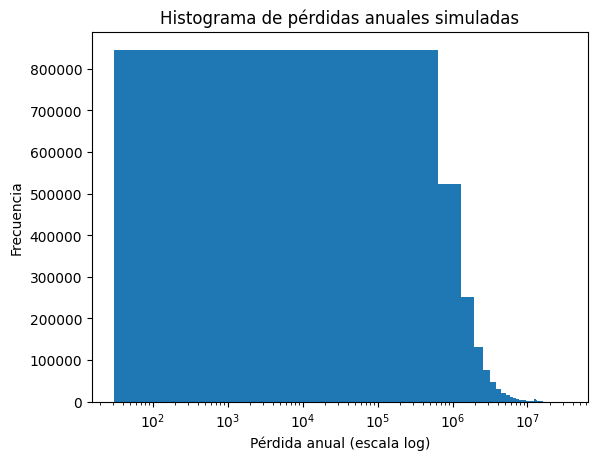

In [47]:
plt.figure()
plt.hist(losses_pos, bins=50)
plt.xscale("log")
plt.xlabel("Pérdida anual (escala log)")
plt.ylabel("Frecuencia")
plt.title("Histograma de pérdidas anuales simuladas")
plt.show()


#### 4.1.6. Revisión de convergencia

In [48]:
def convergence_metrics(losses, freqs, checkpoints):
    rows = []

    for n in checkpoints:
        L = losses[:n]
        F = freqs[:n]

        rows.append({
            "n_sim": n,
            "mean_loss": L.mean(),
            "var_loss": L.var(ddof=1),
           "sd_loss": L.std(ddof=1),
            "p90": np.quantile(L, 0.90),
            "p95": np.quantile(L, 0.95),
            "p99": np.quantile(L, 0.99),
            "freq_mean": F.mean()
        })

    return pd.DataFrame(rows)


In [49]:
losses, sev_sim_all, sev_ret_all, freqs = montecarlo_annual_losses_detail(
    sim_func=sim_annual_loss_zip_lognormal_detail,
    n_sim=5_000_000,
    panel_sub=panel_sub,
    lambda_hat=lambda_hat,
    p_zero=p_zero,
    sigma=sigma_hat,
    loc=loc_hat,
    scale=scale_hat
)

checkpoints = np.arange(1_000, 5_000_001, 1_000)
df_conv = convergence_metrics(losses, freqs, checkpoints)


5,000 simulaciones
10,000 simulaciones
15,000 simulaciones
20,000 simulaciones
25,000 simulaciones
30,000 simulaciones
35,000 simulaciones
40,000 simulaciones
45,000 simulaciones
50,000 simulaciones
55,000 simulaciones
60,000 simulaciones
65,000 simulaciones
70,000 simulaciones
75,000 simulaciones
80,000 simulaciones
85,000 simulaciones
90,000 simulaciones
95,000 simulaciones
100,000 simulaciones
105,000 simulaciones
110,000 simulaciones
115,000 simulaciones
120,000 simulaciones
125,000 simulaciones
130,000 simulaciones
135,000 simulaciones
140,000 simulaciones
145,000 simulaciones
150,000 simulaciones
155,000 simulaciones
160,000 simulaciones
165,000 simulaciones
170,000 simulaciones
175,000 simulaciones
180,000 simulaciones
185,000 simulaciones
190,000 simulaciones
195,000 simulaciones
200,000 simulaciones
205,000 simulaciones
210,000 simulaciones
215,000 simulaciones
220,000 simulaciones
225,000 simulaciones
230,000 simulaciones
235,000 simulaciones
240,000 simulaciones
245,000 simu

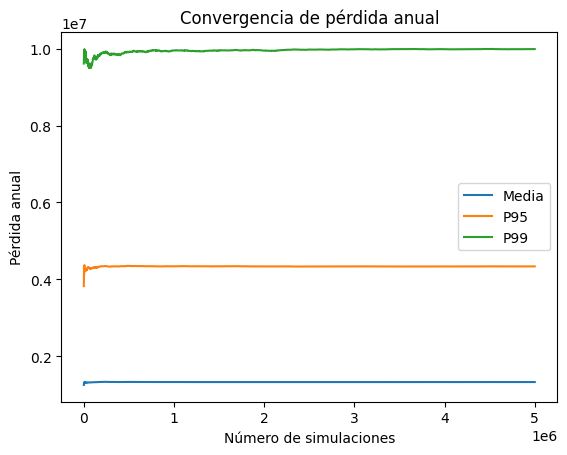

In [50]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(df_conv["n_sim"], df_conv["mean_loss"], label="Media")
plt.plot(df_conv["n_sim"], df_conv["p95"], label="P95")
plt.plot(df_conv["n_sim"], df_conv["p99"], label="P99")
plt.xlabel("Número de simulaciones")
plt.ylabel("Pérdida anual")
plt.legend()
plt.title("Convergencia de pérdida anual")
plt.show()


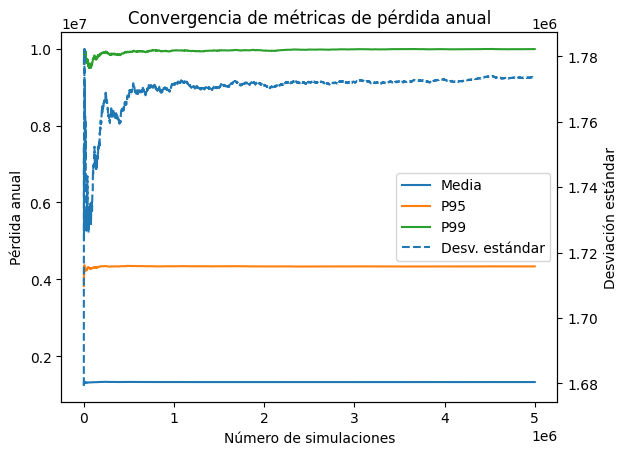

In [51]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots()

# Eje izquierdo: media y cuantiles
ax1.plot(df_conv["n_sim"], df_conv["mean_loss"], label="Media")
ax1.plot(df_conv["n_sim"], df_conv["p95"], label="P95")
ax1.plot(df_conv["n_sim"], df_conv["p99"], label="P99")

ax1.set_xlabel("Número de simulaciones")
ax1.set_ylabel("Pérdida anual")
ax1.set_title("Convergencia de métricas de pérdida anual")

# Eje derecho: desviación estándar (mejor que varianza)
ax2 = ax1.twinx()
ax2.plot(
    df_conv["n_sim"],
    df_conv["sd_loss"],
    linestyle="--",
    label="Desv. estándar"
)
ax2.set_ylabel("Desviación estándar")

# Leyenda combinada
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)

plt.show()


In [52]:
df_conv["p99_rel_change"] = df_conv["p99"].pct_change().abs()
df_conv["mean_rel_change"] = df_conv["mean_loss"].pct_change().abs()


In [53]:
df_conv.tail(100)[
    ["n_sim", "mean_rel_change", "p99_rel_change"]
]


,n_sim,mean_rel_change,p99_rel_change
4900,4901000,0,0
4901,4902000,0,0
4902,4903000,0,0
4903,4904000,0,0
4904,4905000,0,0
...,...,...,...
4995,4996000,0,0
4996,4997000,0,0
4997,4998000,0,0
4998,4999000,0,0


In [54]:
def mc_se(x):
    return x.std(ddof=1) / np.sqrt(len(x))

df_conv["mean_se"] = [
    mc_se(losses[:n]) for n in df_conv["n_sim"]
]
print(df_conv["mean_se"])

0      53,111
1      39,196
2      31,483
3      27,527
4      24,709
        ...  
4995      794
4996      794
4997      793
4998      793
4999      793
Name: mean_se, Length: 5000, dtype: float64


#### 4.1.6. Verificación de métricas de simulaciones

In [55]:
print(freqs.mean())

8.3941848


In [56]:
df_siniestros.columns

Index(['No..Reclamación', 'Año', 'Póliza', 'Producto', 'Suma Asegurada',
       'Cobertura', 'Moneda', 'Estimado + aumento - disminución...8',
       'Estimado + aumento - disminución...9', 'Garantía', 'Monto',
       'Fecha Ocurrido'],
      dtype='object')

In [57]:
print((panel["n_siniestros"] > 0).mean())
print(1-p_zero)

df_siniestros["Fecha Ocurrido"] = pd.to_datetime(df_siniestros["Fecha Ocurrido"])
df_siniestros["anio"] = df_siniestros["Fecha Ocurrido"].dt.year

df_siniestros.groupby("anio").size()

print(df_siniestros.groupby("anio").size().mean())

0.011891653820744329
0.0242796310092791
13.666666666666666


In [58]:
all_sev = np.concatenate(sev_ret_all)

print(all_sev.mean())

print(np.quantile(all_sev, [0.5, 0.9, 0.95, 0.99]))


158608.63037833569
[  28539.154259    315904.56084945  624141.49035753 2241066.03466649]


In [59]:
summary_table_ext = pd.DataFrame({
    "Estadístico": [
        "Observaciones",
        "Media",
        "Mediana",
        "Desv. estándar",
        "P90",
        "P95",
        "P99",
        "P99.5",
        "Máximo"
    ],
    "Valor": [
        len(losses),
        losses.mean(),
        np.median(losses),
        losses.std(ddof=1),
        np.quantile(losses, 0.90),
        np.quantile(losses, 0.95),
        np.quantile(losses, 0.99),
        np.quantile(losses, 0.995),
        losses.max()
    ]
})


In [60]:
summary_table_ext

,Estadístico,Valor
0,Observaciones,"5,000,000"
1,Media,"1,331,390"
2,Mediana,"782,119"
3,Desv. estándar,"1,773,723"
4,P90,"2,911,800"
5,P95,"4,338,557"
6,P99,"9,988,687"
7,P99.5,"12,424,155"
8,Máximo,"33,590,967"


In [61]:
import matplotlib.pyplot as plt

# summary_table_ext = tu DataFrame

fig, ax = plt.subplots(figsize=(12, 6))
ax.axis('off')

tabla = ax.table(
    cellText=summary_table_ext.values,
    colLabels=summary_table_ext.columns,
    loc='center'
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(9)
tabla.scale(1.2, 1.2)

plt.savefig(
    "summary_table_ext.png",
    bbox_inches="tight",
    dpi=300
)
plt.close()

#### 4.1.7. Exportar base

In [62]:
df_annual = pd.DataFrame({
    "sim_id": np.arange(1, len(losses) + 1),
    "loss_annual": losses,
    "n_claims": freqs
})

In [ ]:
rows = []

for sim_id, (sev_sim, sev_ret) in enumerate(
        zip(sev_sim_all, sev_ret_all), start=1
    ):
    for claim_id, (s_sim, s_ret) in enumerate(
            zip(sev_sim, sev_ret), start=1
        ):
        rows.append({
            "sim_id": sim_id,
            "claim_id": claim_id,
            "severity_simulada": s_sim,
            "severity_retenida": s_ret
        })

df_claims = pd.DataFrame(rows)


In [ ]:
# Retención bien aplicada
(df_claims["severity_retenida"] <= df_claims["severity_simulada"]).all()

# Reconstrucción de pérdidas anuales
check = (
    df_claims
    .groupby("sim_id")["severity_retenida"]
    .sum()
    .values
)

np.allclose(check, losses[losses > 0])


In [ ]:
df_annual.to_csv("sim_annual_results_lognormal.csv", index=False)
df_claims.to_csv("sim_claims_lognormal.csv", index=False)


#### 4.1.8. Test de estrés

In [ ]:
def sim_annual_loss_zip_lognormal_detail(
    panel_sub,
    lambda_hat,
    p_zero,
    sigma,
    loc,
    scale,
    retention=12_000_000,
    p_bad=0.05,
    z_bad=4.0
):
    n = len(panel_sub)

    # Stress anual común
    if np.random.rand() < p_bad:
        Z = z_bad
    else:
        Z = 1.0

    # Zeros estructurales
    is_active = np.random.uniform(size=n) > p_zero

    # Frecuencia Poisson con stress
    mu = Z * lambda_hat * panel_sub["exposicion_anual"].values
    freq = np.zeros(n, dtype=int)
    freq[is_active] = poisson.rvs(mu[is_active])

    n_claims = int(freq.sum())
    if n_claims == 0:
        return 0.0, np.array([]), np.array([]), 0

    # Severidad
    sev = lognorm.rvs(
        s=sigma,
        loc=loc,
        scale=scale,
        size=n_claims
    )

    sev_retained = np.minimum(sev, retention)

    return sev_retained.sum(), sev, sev_retained, n_claims


In [ ]:
def montecarlo_annual_losses_detail(
    sim_func,
    n_sim=2_000_000,
    random_seed=123,
    **sim_kwargs
):
    np.random.seed(random_seed)

    losses = np.zeros(n_sim)
    freqs = np.zeros(n_sim, dtype=int)

    severities_sim_all = []
    severities_ret_all = []

    for i in range(n_sim):
        L, sev_sim, sev_ret, n = sim_func(**sim_kwargs)

        losses[i] = L
        freqs[i] = n

        severities_sim_all.append(sev_sim)
        severities_ret_all.append(sev_ret)

        if (i + 1) % 1_000 == 0:
            print(f"{i + 1:,} simulaciones")

    return losses, severities_sim_all, severities_ret_all, freqs


In [ ]:
losses, sev_sim_all, sev_ret_all, freqs = montecarlo_annual_losses_detail(
    sim_func=sim_annual_loss_zip_lognormal_detail,
    n_sim=2_000_000,
    panel_sub=panel_sub,
    lambda_hat=lambda_hat,
    p_zero=p_zero,
    sigma=sigma_hat,
    loc=loc_hat,
    scale=scale_hat,
    p_bad=0.05,
    z_bad=4.0
)


In [ ]:
df_annual = pd.DataFrame({
    "sim_id": np.arange(1, len(losses) + 1),
    "loss_annual": losses,
    "n_claims": freqs
})

In [ ]:
rows = []

for sim_id, (sev_sim, sev_ret) in enumerate(
    zip(sev_sim_all, sev_ret_all), start=1
):
    # Si no hubo siniestros, no se agregan filas
    if len(sev_sim) == 0:
        continue

    for claim_id, (s_sim, s_ret) in enumerate(
        zip(sev_sim, sev_ret), start=1
    ):
        rows.append({
            "sim_id": sim_id,
            "claim_id": claim_id,
            "severity_simulada": float(s_sim),
            "severity_retenida": float(s_ret)
        })

df_claims = pd.DataFrame(rows)


In [ ]:
assert (df_claims["severity_retenida"] <= df_claims["severity_simulada"]).all()


In [ ]:
check = (
    df_claims
    .groupby("sim_id")["severity_retenida"]
    .sum()
)

# Comparar contra pérdidas positivas
losses_pos = pd.Series(losses, index=df_annual["sim_id"]).loc[check.index]

assert np.allclose(check.values, losses_pos.values)


In [ ]:
summary_table_ext = pd.DataFrame({
    "Estadístico": [
        "Observaciones",
        "Media",
        "Mediana",
        "Desv. estándar",
        "P90",
        "P95",
        "P99",
        "P99.5",
        "Máximo"
    ],
    "Valor": [
        len(losses),
        losses.mean(),
        np.median(losses),
        losses.std(ddof=1),
        np.quantile(losses, 0.90),
        np.quantile(losses, 0.95),
        np.quantile(losses, 0.99),
        np.quantile(losses, 0.995),
        losses.max()
    ]
})


In [ ]:
summary_table_ext

In [5]:
plt.figure()

losses_pos = losses[losses > 0]
plt.hist(losses_pos, bins=50, density=True)
plt.xscale("log")

for q, label in zip([0.95, 0.99, 0.995], ["P95", "P99", "P99.5"]):
    plt.axvline(
        np.quantile(losses, q),
        linestyle="--",
        label=label
    )

plt.xlabel("Pérdida anual (escala log)")
plt.ylabel("Densidad")
plt.title("Histograma de pérdidas anuales simuladas")
plt.legend()
plt.show()

NameError: name 'plt' is not defined

In [ ]:
df_annual.to_csv(
    "sim_annual_results_lognormal_test-estres.csv",
    index=False
)

df_claims.to_csv(
    "sim_claims_lognormal_test-estres.csv",
    index=False
)
